# Torsional buckling of ring-stiffened cylinders: Moore and Wescoat (1944), Table I

Moore and Wescoat [1] tested in torsion 24S-T aluminium-alloy cylinders of mean diameter
$D = 30.08$ in, 36 in long overall, with a sheet $t = 0.020$ in thick: specimen 16 without
rings, specimens 17, 18, 13 and 13A with $1/2 \times 1/2$ in solid ring stiffeners inside the
skin. Their Table I (p. 25) gives the average observed shear-buckling stress and the theoretical
one, from Donnell's formula for hinged edges [2]. In the specimens with rings only, buckling is
also the failure ([1] p. 5).

This notebook computes the first buckling stress of the perfect cylinders with
`panels.multidomain.MultiDomain`: the skin is made of curved Kirchhoff-Love domains with the
Sanders-Koiter kinematics, and each ring is a web of annular-sector plate domains connected to the
inner surface of the skin. The stiffened specimens 19, 14, 20, 15 and 21 of the same report are
in the notebook `moore1944_stiffened_cylinders`. The same cases are modelled with BFSC finite
elements in the notebook `moore1944_ring_cylinders` of the bfsccylinder package; its values are
compared in Section 7.

Lengths in in, forces in lbf, stresses in psi, torques in ft-lb as in [1].

In [1]:
import json
import time

import numpy as np
import matplotlib.pyplot as plt

import panels
import moore1944_utils as mu
from moore1944_utils import print_table, rel

%matplotlib inline
print('panels', panels.__version__)
SPECS = ['16', '17', '18', '13', '13A']

panels 0.15.0


## 1. Data

All values are from [1]; "p." is the printed page (the PDF page is two more).

| quantity | value | source |
|---|---|---|
| material, 24S-T | $E = 10.5 \times 10^6$ psi, $\nu = 1/3$ | p. 7 ($G = 3.95 \times 10^6$ psi is also given) |
| mean diameter, overall length | $D = 30.08$ in, 36 in | p. 3, Table I |
| sheet thickness | $t = 0.020$ in | Table I |
| end bulkheads | 3/4 in steel plates, the shell screwed to them | p. 3, Fig. 1 (Section A-A) |
| rings | $1/2 \times 1/2$ in solid 24S-T bars, inside the skin, joined with 3/16 in pins | p. 3, Fig. 1 ("Shell connection to intermediate ring stiffeners") |
| ring stations | Fig. 5, from the centres of the end bulkheads, 35 5/8 in apart | Fig. 5 |
| buckled section, observed and theoretical stresses | Table I | p. 25 |
| stress and torque | $\tau = 0.422\,T$ (psi, ft-lb) for $t = 0.020$ in, i.e. $T = \tau \pi D^2 t/24$ | Fig. 5, note 6; p. 7 |

The bays below are those of Fig. 5: e.g. specimen 13A has rings at 4 5/16, 8 13/16, 17 13/16,
26 13/16 and 31 5/16 in from the centre of the first bulkhead. Specimens 13 and 13A buckled in
different sections: 13 in the end sections (8.81 in), 13A in the intermediate ones (9.00 in,
Fig. 5). Every specimen has a longitudinal stiffener on the seam of the sheet, "not considered
effective in increasing shear-buckling resistance" (p. 4, footnote); it is not modelled.

In [2]:
rows = []
for s in SPECS:
    d = mu.SPECIMENS[s]
    rows.append([s, d['t'], ' | '.join('%g' % b for b in d['bays']), d['panel'], d['obs'],
                 d['theory']])
print_table(rows, ['spec', 't (in)', 'bays (in)', 'buckled section L (in)',
                   'observed (psi)', 'theory [1] (psi)'])

spec  t (in)                            bays (in)  buckled section L (in)  observed (psi)  theory [1] (psi)
----  ------  -----------------------------------  ----------------------  --------------  ----------------
  16    0.02                               35.625                   35.62            1110              1325
  17    0.02                 4.3125 | 27 | 4.3125                   27.00            1280              1520
  18    0.02        4.3125 | 13.5 | 13.5 | 4.3125                   13.50            1710              2210
  13    0.02              8.8125 | 9 | 9 | 8.8125                    8.81            2310              2870
 13A    0.02  4.3125 | 4.5 | 9 | 9 | 4.5 | 4.3125                    9.00            2570              2770


## 2. Moore's theoretical column

Moore and Wescoat computed the theoretical stresses of Table I with Donnell's formula for an
unstiffened cylinder of length $L$ with hinged ends [2], as printed in their appendix ([1] p. 23),
valid for $L^2 t/D^3 < 5.2$:

$$
\tau_0 = \frac{E t^2}{(1 - \nu^2) L^2} \left[2.8 + \sqrt{2.6 + 1.4 \left(\sqrt{1 - \nu^2}\,
\frac{L^2}{t D}\right)^{3/2}}\right]
$$

with $L$ the length of the buckled section, centre to centre of the rings. The rings are taken as
hinged supports.

In [3]:
rows = []
for s in SPECS:
    d = mu.SPECIMENS[s]
    L = float(d['panel'])
    tau0 = mu.donnell_tau(L, d['t'])
    rows.append([s, L, '%.1e' % (L**2*d['t']/mu.D**3), '%.0f' % tau0, d['theory'],
                 '%+.1f' % rel(tau0, d['theory'])])
print_table(rows, ['spec', 'L (in)', 'L^2 t/D^3', 'tau0 (psi)', 'Table I', 'diff %'])

spec  L (in)  L^2 t/D^3  tau0 (psi)  Table I  diff %
----  ------  ---------  ----------  -------  ------
  16   35.62    9.3e-04        1323     1325    -0.2
  17    27.0    5.4e-04        1525     1520    +0.3
  18    13.5    1.3e-04        2204     2210    -0.3
  13    8.81    5.7e-05        2811     2870    -2.1
 13A     9.0    6.0e-05        2775     2770    +0.2


The formula reproduces the column of Table I to 0.4 %, except specimen 13, 2.1 % below the printed
2870 psi; no other length or thickness of the report gives 2870 psi, and the printed value is kept
as Moore's.

## 3. The model

**Domains.** The skin is split along the axis at the ring stations, one bay per ring spacing, and
along the circumference into `nsec` equal sectors. Each domain is a curved `Shell` of the model
`cylshell_clpt_sanders` (Kirchhoff-Love, Sanders-Koiter kinematics) whose fields are series of
Bardell's hierarchical functions [3]; consecutive domains are connected with `'SSxcte'` and
`'SSycte'`, the last sector to the first one to close the cylinder.

**Rings.** Each ring is a web of annular-sector domains of the model `annular_clpt_donnell`, one
per skin sector, of radial height 1/2 in and thickness 1/2 in (the bar), closed with `'SSycte'`.
Its outer edge, at the radius of the inner surface of the skin $R - t/2$, is connected to the end
$x = a$ of the bay before the ring with

```python
dict(p1=skin, p2=ring, func='BFxcte', xcte1=skin.a, xcte2=0., face='lower')
```

which ties the four displacements and the rotation about the circumferential axis of the edge of
the web to those of the inner surface of the skin (Kirchhoff-Love kinematics and the Sanders-Koiter
term $(1 + z/r)\,v$ at the face). This is a continuous bond: the pins of [1] (Fig. 1) are not
represented. The plate theory is a coarse approximation for a bar as thick as it is high: it
represents the bending of the ring in its plane (membrane stiffness of the web) and out of it
(bending of the web) and the eccentricity of the ring; its torsion is that of a Kirchhoff plate.
Rigid ring supports, $v = w = 0$ along the ring line with $w_{,x}$ free, are a sensitivity
(Section 6).

**Ends.** The shell is screwed to 3/4 in steel bulkheads ([1] Fig. 1). The baseline holds $u = v =
w = 0$ at both ends with $w_{,x}$ free, the hinged edges of Moore's theory; clamped ends and $u$
free are sensitivities. The report does not state the end fixity; it says (p. 9) that clamped edges
would raise the theoretical values by 10 to 12 %.

**Load.** A torque $T$ on a perfect circular cylinder gives the uniform membrane shear flow $N_{xy}
= T/(2 \pi R^2)$ in the skin; the rings carry no stress. The pre-buckling state is therefore
exactly the constant $N_{xy}$, given to the skin domains as their attribute `Nxy = 1` lbf/in, and
the critical shear flow is the lowest load multiplier $\lambda$ of

$$
\left(\boldsymbol{K}_r + \lambda \boldsymbol{K}_{G,r}\right) \boldsymbol{\phi}_r = \boldsymbol{0},
\qquad \boldsymbol{K}_r = \boldsymbol{Z}^T \boldsymbol{K} \boldsymbol{Z}, \quad
\boldsymbol{K}_{G,r} = \boldsymbol{Z}^T \boldsymbol{K}_G \boldsymbol{Z}
$$

with $\boldsymbol{Z}$ the basis of the null space of the connections (default `conn_method` of
`MultiDomain`, `'null-space'`), so that $\tau_{cr} = \lambda/t$. Under torsion the load multipliers
come in pairs $\pm\lambda$ and the modes in pairs of the same $\lambda$ (rotated around the axis);
only the sense matters for an anisotropic shell. Section 5 checks the constant shear flow against a
prescribed rotation of one end with the linear static pre-buckling state.

**Runs.** The analyses are run on a cluster node by the script `moore1944_runs.py` of this folder
(stage 1), with the builders of `moore1944_utils.py`, which writes
`results/moore1944_stage1.json`; this notebook reads that file. Meshes:

| mesh | sectors | terms per sector along the circumference | terms per inch along the axis (min. 6, max. 30 per bay) | terms across the ring webs |
|---|---|---|---|---|
| A | 8 | 12 | 0.8 | 6 |
| B | 12 | 14 | 1.0 | 6 |
| C | 12 | 18 | 1.3 | 8 |

In [4]:
with open('results/moore1944_stage1.json') as f:
    RES = json.load(f)
errors = [r for r in RES if 'error' in r]
print('%d cases, %d errors' % (len(RES), len(errors)))
for r in errors:
    print(r['case'], r['spec'], r['error'])
res = {(r['case'], r['spec']): r for r in RES if 'error' not in r}

36 cases, 0 errors


## 4. Convergence

$\tau_{cr}$ (psi) of the first mode, its number of full circumferential waves $n$ in the longest
bay, and the change from the previous mesh.

In [5]:
rows = []
for s in SPECS:
    prev = None
    for mesh in 'ABC':
        r = res[('mesh ' + mesh, s)]
        ch = '' if prev is None else '%+.2f' % rel(r['tau'], prev)
        rows.append([s, mesh, r['domains'], r['size_r'], '%.1f' % r['tau'], ch, r['waves'],
                     '%.0f' % r['seconds']])
        prev = r['tau']
print_table(rows, ['spec', 'mesh', 'domains', 'independent constants', 'tau_cr (psi)',
                   'change %', 'n', 's'])

spec  mesh  domains  independent constants  tau_cr (psi)  change %   n    s
----  ----  -------  ---------------------  ------------  --------  --  ---
  16     A        8                   7232        1401.7            14   12
  16     B       12                  13776        1401.6     -0.01  14   25
  16     C       12                  18096        1401.6     -0.00  14   31
  17     A       40                  10480        1574.7            15   40
  17     B       60                  20928        1574.4     -0.02  15  140
  17     C       60                  31704        1574.4     -0.00  15  416
  18     A       56                  11336        2216.2            19   62
  18     B       84                  22908        2207.4     -0.39  19  241
  18     C       84                  38508        2207.3     -0.00  19  841
  13     A       56                   9800        2800.4            22   37
  13     B       84                  21084        2736.4     -2.29  22  285
  13     C  

## 5. Cross-check: torque from a prescribed end rotation

For specimen 18 (mesh B) the end $x = L$ is rotated about the axis by $\theta = 10^{-3}$, $v =
\theta R$, with $u = w = 0$ there and the other end held; the prescribed displacements are imposed
exactly (`pd_method='null-space'`). The torque at load factor 1 is the reaction work-conjugate to
the prescribed displacements divided by $\theta$ (`MultiDomain.reaction_pd`), and the linear
buckling analysis about the linear static state (`MultiDomain.linear_buckling`) gives the critical
torque.

In [6]:
r_rot = res[('end rotation', '18')]
r_cte = res[('mesh B', '18')]
GJ = mu.E/(2*(1 + mu.NU))*2*np.pi*mu.R**3*0.020
print('torque at theta = 1e-3: %.1f lbf in; G J theta/L = %.1f lbf in (thin-walled tube)'
      % (r_rot['T']/r_rot['ev'][0]*12, GJ*1e-3/sum(mu.SPECIMENS['18']['bays'])))
print('tau_cr: end rotation %.2f psi, constant shear flow %.2f psi, difference %.4f %%'
      % (r_rot['tau'], r_cte['tau'], rel(r_rot['tau'], r_cte['tau'])))

torque at theta = 1e-3: 47251.9 lbf in; G J theta/L = 47251.9 lbf in (thin-walled tube)
tau_cr: end rotation 2207.45 psi, constant shear flow 2207.45 psi, difference 0.0000 %


## 6. Sensitivity to the data that are not given

Mesh B, one change at a time: clamped ends ($w_{,x} = 0$ also); $u$ free at the ends; rigid ring
supports instead of the ring webs; the Donnell kinematics in the skin
(`cylshell_clpt_donnell`).

In [7]:
SENS = ['clamped', 'u free', 'rigid rings', 'Donnell skin']
rows = []
for s in SPECS:
    base = res[('mesh B', s)]['tau']
    row = [s, '%.1f' % base]
    for name in SENS:
        r = res.get((name, s))
        row += ['%.1f (%+.1f %%)' % (r['tau'], rel(r['tau'], base)) if r else 'n/a']
    rows.append(row)
print_table(rows, ['spec', 'baseline'] + SENS)

spec  baseline          clamped           u free      rigid rings     Donnell skin
----  --------  ---------------  ---------------  ---------------  ---------------
  16    1401.6  1403.9 (+0.2 %)  1351.8 (-3.5 %)  1401.6 (+0.0 %)  1403.3 (+0.1 %)
  17    1574.4  1574.5 (+0.0 %)  1574.4 (-0.0 %)  1562.5 (-0.8 %)  1575.8 (+0.1 %)
  18    2207.4  2207.5 (+0.0 %)  2207.4 (-0.0 %)  2156.3 (-2.3 %)  2208.1 (+0.0 %)
  13    2736.4  2738.6 (+0.1 %)  2697.7 (-1.4 %)  2653.6 (-3.0 %)  2736.7 (+0.0 %)
 13A    2744.0  2744.0 (+0.0 %)  2744.0 (-0.0 %)  2667.0 (-2.8 %)  2744.6 (+0.0 %)


## 7. Comparison with Table I and with bfsccylinder

$\tau_{FE}$ is the first buckling stress of the perfect cylinder, mesh C, hinged ends ($u = v = w
= 0$). The bfsccylinder values are those of the notebook `moore1944_ring_cylinders` of that package
(BFSC cylinder elements of Sanders-type kinematics, ring as a band of skin elements with the
laminate skin + bar, same ends, Bloch sectors): 1403, 1592, 2252, 2810 and 2829 psi for specimens
16, 17, 18, 13 and 13A.

In [8]:
BFSC = {'16': 1403, '17': 1592, '18': 2252, '13': 2810, '13A': 2829}
rows = []
for s in SPECS:
    d = mu.SPECIMENS[s]
    r = res[('mesh C', s)]
    rows.append([s, d['panel'], r['waves'], '%.0f' % r['tau'], '%.0f' % r['T'], d['obs'],
                 '%.0f' % mu.torque_ftlb(d['obs'], d['t']), d['theory'],
                 '%+.1f' % rel(r['tau'], d['obs']), '%+.1f' % rel(r['tau'], d['theory']),
                 BFSC[s], '%+.1f' % rel(r['tau'], BFSC[s])])
print_table(rows, ['spec', 'L (in)', 'n', 'tau_FE (psi)', 'T_FE (ft-lb)', 'observed (psi)',
                   'observed (ft-lb)', 'theory [1]', 'FE vs obs %', 'FE vs theory %',
                   'bfsccylinder', 'panels vs bfsc %'])

spec  L (in)   n  tau_FE (psi)  T_FE (ft-lb)  observed (psi)  observed (ft-lb)  theory [1]  FE vs obs %  FE vs theory %  bfsccylinder  panels vs bfsc %
----  ------  --  ------------  ------------  --------------  ----------------  ----------  -----------  --------------  ------------  ----------------
  16   35.62  14          1402          3320            1110              2629        1325        +26.3            +5.8          1403              -0.1
  17   27.00  15          1574          3729            1280              3032        1520        +23.0            +3.6          1592              -1.1
  18   13.50  19          2207          5229            1710              4051        2210        +29.1            -0.1          2252              -2.0
  13    8.81  22          2732          6471            2310              5472        2870        +18.3            -4.8          2810              -2.8
 13A    9.00  22          2740          6490            2570              6088        27

## 8. Buckling modes

Radial displacement $w$ of the first mode on the unrolled skin (mesh C, arbitrary scale); the
dashed lines are the rings.

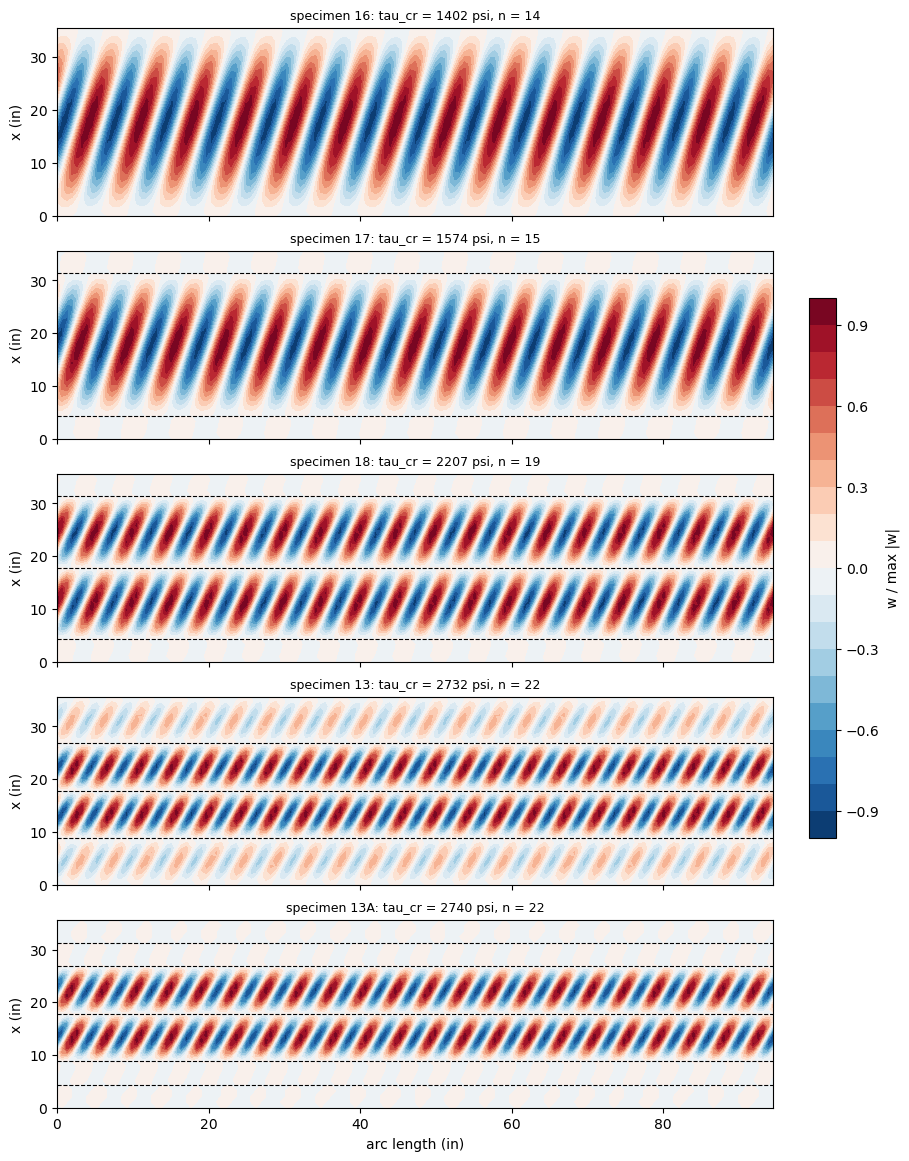

In [9]:
fig, axes = plt.subplots(len(SPECS), 1, figsize=(9, 2.3*len(SPECS)), sharex=True,
                         constrained_layout=True)
for ax, s in zip(axes, SPECS):
    r = res[('mesh C', s)]
    mode = r['mode']
    wmax = max(np.abs(np.array(W)).max() for W in mode['W'])
    for X, S, W in zip(mode['X'], mode['S'], mode['W']):
        cs = ax.contourf(np.array(S), np.array(X), np.array(W)/wmax,
                         levels=np.linspace(-1, 1, 21), cmap='RdBu_r')
    x = 0.
    for b in mu.SPECIMENS[s]['bays'][:-1]:
        x += b
        ax.axhline(x, color='k', ls='--', lw=0.8)
    ax.set_ylabel('x (in)')
    ax.set_title('specimen %s: tau_cr = %.0f psi, n = %d' % (s, r['tau'], r['waves']),
                 fontsize=9)
axes[-1].set_xlabel('arc length (in)')
fig.colorbar(cs, ax=axes, shrink=0.5, label='w / max |w|')
plt.show()

## 9. Discussion

- **Convergence.** The last refinement changes $\tau_{cr}$ by 0.17 % or less (Section 4); the
  first mode has 14 to 22 full waves along the circumference, more than the wavelengths measured in
  [1] (Fig. 5: $W = 9$ in for specimen 16, about 10.5 waves), as Moore and Wescoat also found
  against Donnell's theory (p. 9).
- **Pre-buckling state.** The prescribed end rotation gives the torsional stiffness of the thin
  tube, $G J/L$ with $J = 2 \pi R^3 t$, and the same buckling stress as the constant shear flow to
  $10^{-6}$: the rings carry no stress before buckling, and the constant $N_{xy}$ is the exact
  pre-buckling state.
- **Specimen 16 and Donnell's formula.** With $u = v = w = 0$ at both ends the model is 5.8 %
  above Moore's theoretical value; with $u$ free at the loaded end it is 1352 psi, 2.2 % above
  Donnell's 1323 psi. The end fixity is not given in [1]; clamping the ends ($w_{,x} = 0$) raises
  $\tau_{cr}$ by 0.2 % only, whereas [1] (p. 9) expects 10 to 12 % for clamped edges.
- **Ring-stiffened specimens.** The model is 3.6 % above to 4.8 % below Moore's column, which
  takes each bay as an unstiffened cylinder with hinged ends. Rigid ring supports with $w_{,x}$
  free lower $\tau_{cr}$ by 0.8 to 3.0 %: the ring webs restrain the rotation $w_{,x}$ of the skin
  in addition to $v$ and $w$. Specimen 13 buckled in its end bays (8.81 in, Table I), the first mode of
  the model has its largest buckles in the two 9 in intermediate bays and smaller ones in the end
  bays (Section 8); its stress is 0.3 % below that of 13A, which buckled in the 9 in intermediate
  bays in the test and in the model. Moore and Wescoat explain the lower observed stress of 13 by a
  less uniform shear near the bulkheads (p. 9), which the model, with a uniform shear flow, does
  not have.
- **Test values.** The observed stresses are 6.6 to 29 % below those of the perfect cylinders,
  within the range that [1] reports, 77 to 93 % of the theory (Table I); [1] attributes the
  difference to local out-of-roundness and initial buckles (p. 9), and the repeated tests of a
  specimen gave minima of 83 to 98 % of the maxima (p. 8).
- **bfsccylinder.** The BFSC model gives 0.1 % (specimen 16) to 3.2 % (13A) more. The difference
  grows with the number of rings, which are modelled differently: here as annular plate webs on the
  inner face, there as bands of skin elements with the laminate skin + bar, whose Kirchhoff
  torsional stiffness is 2.4 times the St Venant value of the bar (bfsccylinder notebook); both
  ring models restrain the rotation of the skin.
- **Not represented.** The pins joining the rings to the skin, the seam stiffener, the splices of
  the rings and the initial imperfections.

## References

1. Moore, R. L., and Wescoat, C., "Torsion Tests of Stiffened Circular Cylinders", NACA ARR 4E31
   (Wartime Report W-89), 1944: Table I p. 25, appendix p. 23, Figs. 1 and 5.
2. Donnell, L. H., "Stability of Thin-Walled Tubes under Torsion", NACA Report 479, 1933 (as
   given in [1], p. 23).
3. Castro, S. G. P., and Donadon, M. V., "Assembly of semi-analytical models to address linear
   buckling and vibration of stiffened composite panels with debonding defect", Composite
   Structures, 160, 2017, pp. 232-247, doi:10.1016/j.compstruct.2016.10.026.